# 07 · Complete mock-SBI SNLE overview: $gX$, $g^2X$, and matched $gX+g^2X$

This notebook contains the established two-point mock-SBI comparison followed by the
all-256 native-replica rerun. The updated section compares $gX$, $g^2X$, and their
separately normalized 10D combination for $X=y,\kappa,\tau$, and includes
score-support, held-out-likelihood, sampler-repeat, and network-seed diagnostics.

The all-256 section reads its master product and nine posterior files from
\`data/SBI_validate/mock_sbi/all256_native/\`. The pooled old/new result remains
exploratory because the two cohorts were generated from different scientific source
snapshots.

NLE is used rather than NPE: it learns \`p(x | theta)\` and applies the box prior
analytically during MCMC.


In [1]:
import json, os, pathlib, sys
import numpy as np, h5py
import matplotlib.pyplot as plt
_cwd = pathlib.Path.cwd().resolve()
_root_candidates = ([pathlib.Path(os.environ["GODMAX_REPO"]).expanduser()]
                    if os.environ.get("GODMAX_REPO") else [])
_root_candidates += [_cwd, *_cwd.parents,
                     pathlib.Path("/work/hdd/bdne/aacharya2/GODMAX"),
                     pathlib.Path("/mnt/ceph/users/spandey/ltu-godmax/GODMAX")]
ROOT = next((p.resolve() for p in _root_candidates
             if (p / "notebooks/SBI_validate").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Cannot locate GODMAX; set GODMAX_REPO to the checkout root")
sys.path.insert(0, str(ROOT / "notebooks/SBI_validate/common"))
DATA = ROOT / "data/SBI_validate"
VAL  = DATA / "three_probe_mock/validation"
INF  = DATA / "three_probe_inference"
MSBI = DATA / "mock_sbi"
BLUE, ORANGE, GREEN, INK2, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#dedcd6"
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.edgecolor": GRID, "xtick.color": INK2, "ytick.color": INK2,
                     "font.size": 10.5, "axes.spines.top": False, "axes.spines.right": False})
SPECTRA = ["gy", "gkappa", "gtau"]
LBL = {"gg": r"$g \times g$", "gy": r"$g \times y$",
       "gkappa": r"$g \times \kappa_{\rm CMB}$", "gtau": r"$g \times \tau$"}

In [2]:
PARAMS = ["theta_ej_0", "alpha_nt", "mu_beta", "theta_co_0", "nu_theta_ej_M"]
post = np.load(MSBI / "trial/mock_snle_n0038_posterior.npz", allow_pickle=True)
mock, u_mock = np.asarray(post["theta"]), np.asarray(post["u"])
man = json.loads(str(post["manifest_json"]))
print(f"{man['estimator']}  ->  {mock.shape[0]:,} samples")
print(f"  {man['n_pasted_points']} pasted points x "
      f"{man['n_training_rows']//man['n_pasted_points']} noise draws = "
      f"{man['n_training_rows']:,} rows")
print(f"  {man['seeds']} pooled network seeds; largest single-seed departure "
      f"{man['max_seed_departure_sigma']:.3f} sigma")
print(f"  proposal correction required: {man['proposal_correction_required']}")
print(f"  observation: {man['observation_kind']}")

SNLE (NLE, one round)  ->  80,000 samples
  94 pasted points x 64 noise draws = 6,016 rows
  4 pooled network seeds; largest single-seed departure 0.397 sigma
  proposal correction required: False
  observation: pasted_map_measurement_noiseless


### Seed-to-seed spread\n\nA single NLE seed is not quotable; the ensemble spread is the reason the run pools four.

orange line = the pooled mean


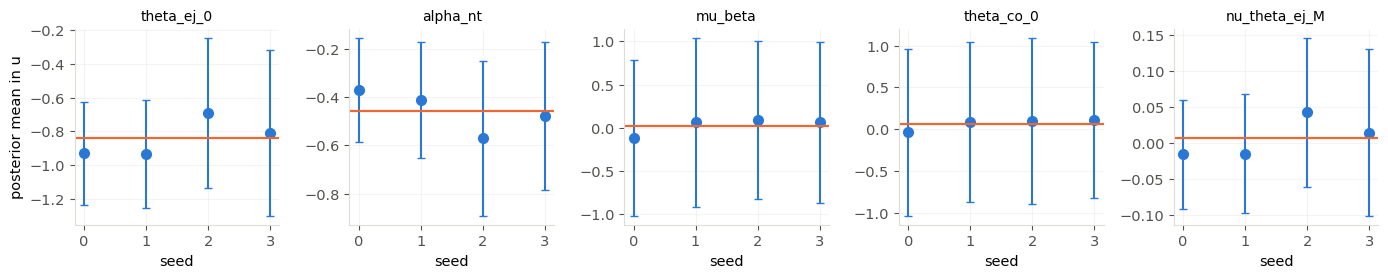

In [3]:
seeds = [np.asarray(post[f"u_seed_{i}"]) for i in range(man["seeds"])]
fig, axes = plt.subplots(1, 5, figsize=(14, 2.9))
for j, (ax, p) in enumerate(zip(axes, PARAMS)):
    for i, s in enumerate(seeds):
        ax.plot(i, s[:, j].mean(), "o", ms=7, color=BLUE)
        ax.errorbar(i, s[:, j].mean(), yerr=s[:, j].std(ddof=1), color=BLUE, capsize=3)
    ax.axhline(u_mock[:, j].mean(), color=ORANGE, lw=1.6)
    ax.set_title(p, fontsize=10); ax.set_xlabel("seed"); ax.set_xticks(range(len(seeds)))
    ax.grid(alpha=.3, color=GRID)
axes[0].set_ylabel("posterior mean in u")
fig.tight_layout()
print("orange line = the pooled mean")

### All three posteriors

In [4]:
# Constants are defined here rather than imported from plot_three_way_triangle.py:
# that module calls matplotlib.use("Agg") at import, which switches the backend away
# from the notebook's inline one and silently stops every later figure displaying.
TRUTH = np.array([2.0, 0.18, 0.6, 0.05, 0.0])
LABELS = [r"$\theta_{\rm ej,0}$", r"$\alpha_{\rm nt}$", r"$\mu_\beta$",
          r"$\theta_{\rm co,0}$", r"$\nu_{\theta_{\rm ej},M}$"]

In [5]:
raw = np.load(INF / "hmc_sc/run01/hmc_samples.npz")
hmc = np.stack([np.asarray(raw[f"sample_{p}"]).reshape(-1) for p in PARAMS], 1)
u_hmc = np.asarray(raw["u"]).reshape(-1, 5)
sbi = np.load(INF / "sbi_sc/run01/posterior_samples_round_4.npz")
npe, u_npe = np.asarray(sbi["theta"]), np.asarray(sbi["u"])

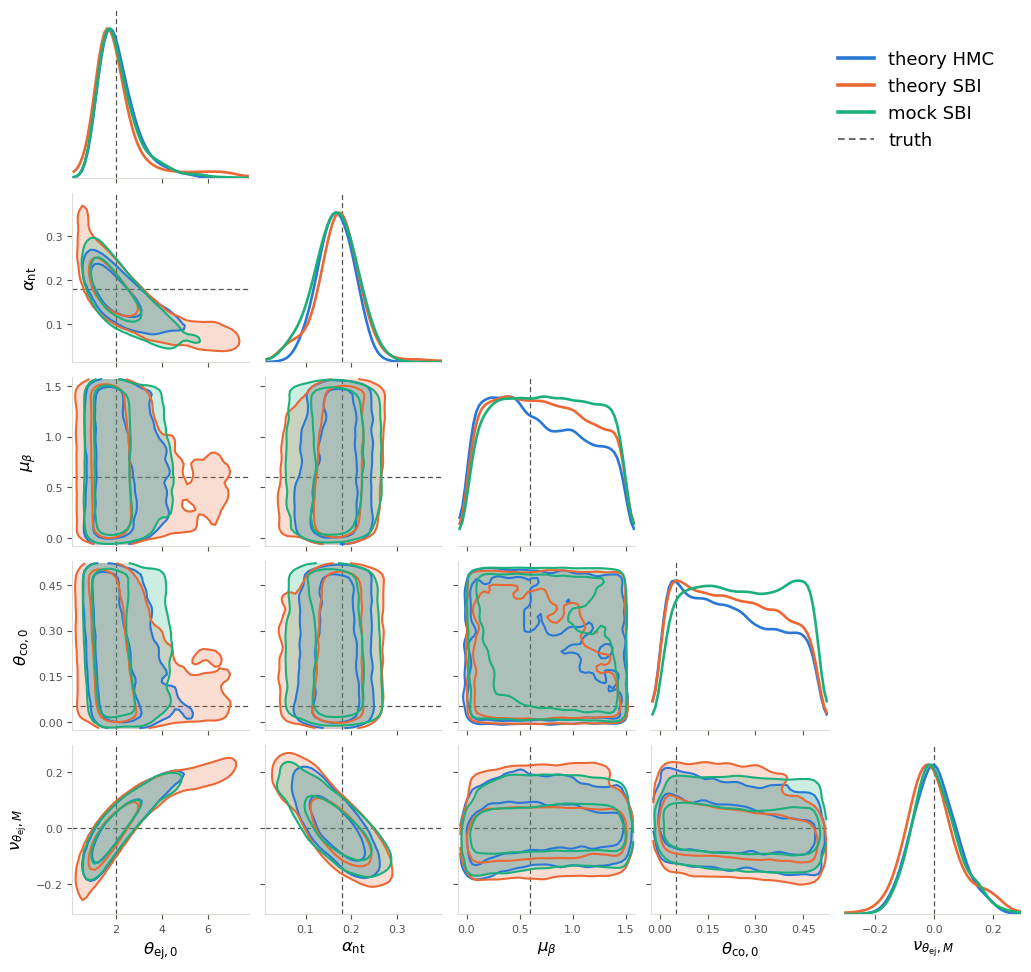

In [6]:
from scipy.ndimage import gaussian_filter
from matplotlib.lines import Line2D
def triangle(chains, colors, names, points=None):
    n, B1, S1, B2, S2 = 5, 64, 2.4, 44, 1.35
    lo, hi = np.empty(n), np.empty(n)
    for j in range(n):
        q = np.concatenate([np.percentile(c[:, j], [0.3, 99.7]) for c in chains])
        if points is not None: q = np.r_[q, points[:, j].min(), points[:, j].max()]
        pad = .06 * (q.max() - q.min()); lo[j], hi[j] = q.min() - pad, q.max() + pad
    fig, ax = plt.subplots(n, n, figsize=(10.6, 10.0))
    for i in range(n):
        for j in range(n):
            a = ax[i, j]
            if j > i: a.axis("off"); continue
            if i == j:
                for c, col in zip(chains, colors):
                    h, e = np.histogram(c[:, j], bins=B1, range=(lo[j], hi[j]), density=True)
                    h = gaussian_filter(h, S1); a.plot(.5*(e[:-1]+e[1:]), h/h.max(), color=col, lw=1.9)
                a.set_ylim(0, 1.13); a.set_yticks([]); a.spines["left"].set_visible(False)
            else:
                for kk, (c, col) in enumerate(zip(chains, colors)):
                    H, xe, ye = np.histogram2d(c[:, j], c[:, i], bins=B2,
                                               range=[[lo[j], hi[j]], [lo[i], hi[i]]])
                    H = gaussian_filter(H.T, S2)
                    if H.max() <= 0: continue
                    f = np.sort(H.ravel())[::-1]; cs = np.cumsum(f); cs /= cs[-1]
                    lv = sorted({float(f[min(int(np.searchsorted(cs, q)), f.size-1)])
                                 for q in (.68, .95)})
                    xc, yc = .5*(xe[:-1]+xe[1:]), .5*(ye[:-1]+ye[1:])
                    a.contourf(xc, yc, H, levels=lv+[H.max()*1.001], colors=col, alpha=.22, zorder=1+kk)
                    a.contour(xc, yc, H, levels=lv, colors=col, linewidths=1.5, zorder=5+kk)
                if points is not None:
                    a.plot(points[:, j], points[:, i], "o", ms=3.2, mfc="none", mec="k",
                           mew=.75, alpha=.85, zorder=20)
                a.set_ylim(lo[i], hi[i])
            a.axvline(TRUTH[j], color=INK2, lw=.9, ls=(0,(4,2.5)), zorder=0)
            if i != j: a.axhline(TRUTH[i], color=INK2, lw=.9, ls=(0,(4,2.5)), zorder=0)
            a.set_xlim(lo[j], hi[j]); a.tick_params(labelsize=8)
            a.xaxis.set_major_locator(plt.MaxNLocator(4, prune="both"))
            if i != j: a.yaxis.set_major_locator(plt.MaxNLocator(4, prune="both"))
            if i == n-1: a.set_xlabel(LABELS[j], fontsize=12)
            else: a.set_xticklabels([])
            if j == 0 and i > 0: a.set_ylabel(LABELS[i], fontsize=12)
            elif j != 0: a.set_yticklabels([])
    hs = [Line2D([], [], color=c, lw=2.6, label=nm) for c, nm in zip(colors, names)]
    if points is not None:
        hs.append(Line2D([], [], color="k", marker="o", ms=5, mfc="none", ls="none",
                         label="design points"))
    hs.append(Line2D([], [], color=INK2, lw=1.2, ls=(0,(4,2.5)), label="truth"))
    fig.legend(handles=hs, loc="upper right", bbox_to_anchor=(.975, .96), frameon=False,
               fontsize=13)
    fig.subplots_adjust(left=.09, right=.985, top=.985, bottom=.08, wspace=.09, hspace=.09)
    return fig
_ = triangle([hmc, npe, mock], [BLUE, ORANGE, GREEN],
             ["theory HMC", "theory SBI", "mock SBI"])

### Mean drift and 90% width ratio against theory HMC

In [7]:
w90 = lambda x: np.percentile(x, 95, 0) - np.percentile(x, 5, 0)
print(f"{'parameter':<16}{'SBI drift':>11}{'SBI w90':>9}{'mock drift':>12}{'mock w90':>10}")
for j, p in enumerate(PARAMS):
    print(f"{p:<16}"
          f"{(u_npe[:,j].mean()-u_hmc[:,j].mean())/u_hmc[:,j].std(ddof=1):>+11.3f}"
          f"{w90(u_npe)[j]/w90(u_hmc)[j]:>9.3f}"
          f"{(u_mock[:,j].mean()-u_hmc[:,j].mean())/u_hmc[:,j].std(ddof=1):>+12.3f}"
          f"{w90(u_mock)[j]/w90(u_hmc)[j]:>10.3f}")

parameter         SBI drift  SBI w90  mock drift  mock w90
theta_ej_0           -0.075    1.547      +0.014     1.086
alpha_nt             +0.089    1.415      -0.074     1.340
mu_beta              +0.105    0.977      +0.175     0.945
theta_co_0           +0.042    0.982      +0.233     0.964
nu_theta_ej_M        -0.130    1.223      +0.021     1.025


**Status.** This is the 94-point trial, not the full 128-point round. Against the relaxed
gate (0.20 sigma drift, 20% width) `theta_co_0` drift and `alpha_nt` width both fail;
`mu_beta` and `theta_co_0` are unconstrained by these three spectra (posterior sd ~= prior
sd), so their drifts are wobbles in a near-flat marginal. On widths, mock SBI is closer to
theory HMC than theory SBI is in four of five parameters.

---

## All-256 native-replica SNLE: $gX$, $g^2X$, and matched $gX+g^2X$

This replaces the old 104-point, five-replica pilot section. It loads the combined/native
job-29 outputs: 128 repaired round-1 points with five map-noise realisations per point and
128 new round-2 points with ten, for 1,920 native rows. The frozen point split holds out
13 points from each cohort.

The nine posterior files are $gX$, $g^2X$, and their paired 10D score concatenation
for each of $X=y,\kappa,\tau$. In each joint fit, the two 14-bin blocks are separately
whitened and compressed to 5D, then concatenated without addition. The next cell verifies
the saved contracts and prints the
actual training and MCMC settings, including the sample count that was really written.
The notebook does not assume a fixed pooled-draw count.

These products remain exploratory. Point holdout and stability diagnostics are stronger
than the old pilot checks, but do not establish calibrated coverage.


In [8]:
ALL256_DIR = MSBI / "all256_native"
ALL256_MASTER_FILE = ALL256_DIR / "gx_g2x_native_all256.npz"
ALL256_RUN_LABEL = "combined_native_contractnative"
ALL256_FIG_DIR = ALL256_DIR / "figures"

ALL256_FIELDS = [
    ("y", r"$y$", ("gy", "g2y", "gy_g2y")),
    ("kappa", r"$\kappa_{\rm CMB}$",
     ("gkappa", "g2kappa", "gkappa_g2kappa")),
    ("tau", r"$\tau$", ("gtau", "g2tau", "gtau_g2tau")),
]
ALL256_PROBES = [p for _, _, probes in ALL256_FIELDS for p in probes]
ALL256_JOINT_PROBES = {"gy_g2y", "gkappa_g2kappa", "gtau_g2tau"}
ALL256_POST_FILES = {
    # Existing individual-statistic results.
    "gy": ALL256_DIR / f"mock_snle_all256_{ALL256_RUN_LABEL}_gy_posterior.npz",
    "g2y": ALL256_DIR / f"mock_snle_all256_{ALL256_RUN_LABEL}_g2y_posterior.npz",
    "gkappa": ALL256_DIR / f"mock_snle_all256_{ALL256_RUN_LABEL}_gkappa_posterior.npz",
    "g2kappa": ALL256_DIR / f"mock_snle_all256_{ALL256_RUN_LABEL}_g2kappa_posterior.npz",
    "gtau": ALL256_DIR / f"mock_snle_all256_{ALL256_RUN_LABEL}_gtau_posterior.npz",
    "g2tau": ALL256_DIR / f"mock_snle_all256_{ALL256_RUN_LABEL}_g2tau_posterior.npz",
    # Joint results: separately normalized 5D scores concatenated to 10D.
    "gy_g2y": ALL256_DIR / f"mock_snle_all256_{ALL256_RUN_LABEL}_sepscore10_gy_g2y_posterior.npz",
    "gkappa_g2kappa": ALL256_DIR / f"mock_snle_all256_{ALL256_RUN_LABEL}_sepscore10_gkappa_g2kappa_posterior.npz",
    "gtau_g2tau": ALL256_DIR / f"mock_snle_all256_{ALL256_RUN_LABEL}_sepscore10_gtau_g2tau_posterior.npz",
}
ALL256_NAMES = {
    "gy": r"$g\times y$", "g2y": r"$g^2\times y$",
    "gy_g2y": r"$gy+g^2y$",
    "gkappa": r"$g\times\kappa_{\rm CMB}$",
    "g2kappa": r"$g^2\times\kappa_{\rm CMB}$",
    "gkappa_g2kappa": r"$g\kappa+g^2\kappa$",
    "gtau": r"$g\times\tau$", "g2tau": r"$g^2\times\tau$",
    "gtau_g2tau": r"$g\tau+g^2\tau$",
}
ALL256_COLORS = (BLUE, ORANGE, GREEN)  # gX, g²X, joint

def _manifest(npz):
    raw = np.asarray(npz["manifest_json"])
    if raw.shape != ():
        raise ValueError(f"manifest_json has shape {raw.shape}, expected scalar")
    return json.loads(raw.item())

def _require(ok, message):
    if not ok:
        raise ValueError(message)

required = [ALL256_MASTER_FILE, ALL256_MASTER_FILE.with_suffix(".json")]
for path in ALL256_POST_FILES.values():
    required += [path, path.with_suffix(".json")]
missing = [path for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError(
        "Missing all-256 files; finish job 29 or change ALL256_RUN_LABEL:\n  "
        + "\n  ".join(map(str, missing))
    )
ALL256_FIG_DIR.mkdir(parents=True, exist_ok=True)

all256_master = np.load(ALL256_MASTER_FILE, allow_pickle=False)
all256_master_man = _manifest(all256_master)
all256_posts = {
    p: np.load(path, allow_pickle=False)
    for p, path in ALL256_POST_FILES.items()
}
all256_man = {p: _manifest(post) for p, post in all256_posts.items()}

_require(
    json.loads(ALL256_MASTER_FILE.with_suffix(".json").read_text())
    == all256_master_man,
    "master NPZ manifest and JSON sidecar differ",
)
_require(all256_master_man["schema_version"]
         == "godmax.mock_sbi.gx_g2x_native_heterogeneous.v3",
         "unexpected master schema")
_require(all256_master_man["n_points"] == 256, "master point count is not 256")
_require(all256_master_man["n_rows"] == 1920, "master row count is not 1,920")
_require(all256_master_man["replica_count_histogram"] == {"5": 128, "10": 128},
         "master is not the registered 128×5 plus 128×10 product")
_require(tuple(all256_master_man["parameter_names"]) == tuple(PARAMS),
         "master parameter order differs")
split_info = all256_master_man["point_split"]
_require((split_info["training_points"], split_info["validation_points"],
          split_info["validation_old"], split_info["validation_new"])
         == (230, 26, 13, 13), "unexpected frozen point split")

all256_split = np.asarray(all256_master["point_split"], dtype=np.int8)
all256_point_index = np.asarray(all256_master["point_index"], dtype=np.int64)
all256_design_theta = np.asarray(all256_master["point_theta"], dtype=float)
all256_truth = np.asarray(all256_master["theta_reference"], dtype=float)
np.testing.assert_allclose(all256_truth, TRUTH, rtol=0, atol=0)

for probe, path in ALL256_POST_FILES.items():
    post, man = all256_posts[probe], all256_man[probe]
    _require(json.loads(path.with_suffix(".json").read_text()) == man,
             f"{probe}: NPZ manifest and JSON sidecar differ")
    is_joint = probe in ALL256_JOINT_PROBES
    expected_schema = (
        "godmax.mock_sbi.all256_native_snle_separate_score_concat10.v1"
        if is_joint else "godmax.mock_sbi.all256_native_snle_posterior.v1"
    )
    expected_status = (
        "exploratory_two_snapshot_all256_separate_score_concat10"
        if is_joint else "exploratory_two_snapshot_all256_snle"
    )
    _require(man["schema_version"] == expected_schema,
             f"{probe}: unexpected posterior schema")
    _require(man["analysis_status"] == expected_status,
             f"{probe}: unexpected analysis status")
    _require(man["summary_dimension"] == (10 if is_joint else 5),
             f"{probe}: unexpected summary dimension")
    _require(man["probe"] == probe, f"{probe}: probe label mismatch")
    _require((man["cohort"], man["training_replica_policy"],
              man["contract_replica_policy"])
             == ("combined", "native", "native"),
             f"{probe}: not the combined/native/contract-native run")
    _require(tuple(man["parameter_names"]) == tuple(PARAMS),
             f"{probe}: parameter order differs")
    _require((man["n_master_points"], man["n_master_native_rows"])
             == (256, 1920), f"{probe}: wrong master dimensions")
    _require(man["point_split_sha256"] == split_info["sha256"],
             f"{probe}: frozen point split hash differs")
    _require(np.array_equal(np.asarray(post["point_split"]), all256_split),
             f"{probe}: point split array differs")
    np.testing.assert_allclose(post["theta_reference"], all256_truth, rtol=0, atol=0)
    theta_shape = np.asarray(post["theta"]).shape
    u_shape = np.asarray(post["u"]).shape
    _require(len(theta_shape) == 2 and theta_shape[1] == 5,
             f"{probe}: invalid theta shape {theta_shape}")
    _require(u_shape == theta_shape,
             f"{probe}: u shape {u_shape} differs from theta {theta_shape}")
    _require(man["pooled_samples"] == theta_shape[0],
             f"{probe}: manifest/sample-array row count differs")
    _require(man["network_seeds"] == 4,
             f"{probe}: expected four trained networks")
    _require(man["posterior_samples_per_network"] * man["network_seeds"]
             == man["pooled_samples"],
             f"{probe}: pooled count is inconsistent with its network counts")

print(all256_master_man["source_snapshot_warning"])
print(f"master: 256 points, 1,920 rows; "
      f"{split_info['training_points']} train / "
      f"{split_info['validation_points']} held out")
print(f"{'probe':20s} {'rows train/held':>16s} {'batch':>7s} "
      f"{'patience':>9s} {'max ep':>7s} {'warmup':>7s} {'pooled':>10s}")
for probe in ALL256_PROBES:
    man = all256_man[probe]
    train, mcmc = man["training"], man["mcmc"]
    print(f"{probe:20s} {man['n_training_rows']:6d}/{man['n_heldout_rows']:<6d} "
          f"{train['training_batch_size']:7d} "
          f"{train['stop_after_epochs']:9d} {train['max_num_epochs']:7d} "
          f"{mcmc['warmup_steps']:7d} {man['pooled_samples']:10,d}")


old and new scientific source snapshots differ; pooled inference is exploratory
master: 256 points, 1,920 rows; 230 train / 26 held out
probe                 rows train/held   batch  patience  max ep  warmup     pooled
gy                     1725/195         64       100    2000    1000     80,000
g2y                    1725/195         64       100    2000    1000     80,000
gy_g2y                 1725/195        512        25     500     250     80,000
gkappa                 1725/195         64       100    2000    1000     80,000
g2kappa                1725/195         64       100    2000    1000     80,000
gkappa_g2kappa         1725/195        512        25     500     250     80,000
gtau                   1725/195         64       100    2000    1000     80,000
g2tau                  1725/195         64       100    2000    1000     80,000
gtau_g2tau             1725/195        512        25     500     250     80,000


### Sampler-repeat, network-seed, and held-out diagnostics

Each likelihood was sampled twice with independent MCMC seeds. The orange curve is the
largest repeat-to-repeat posterior-mean shift; the blue curve is the largest trained-network
mean departure. Both are expressed in pooled marginal standard deviations. They test
sampling and learned-likelihood stability separately and are not coverage statistics.


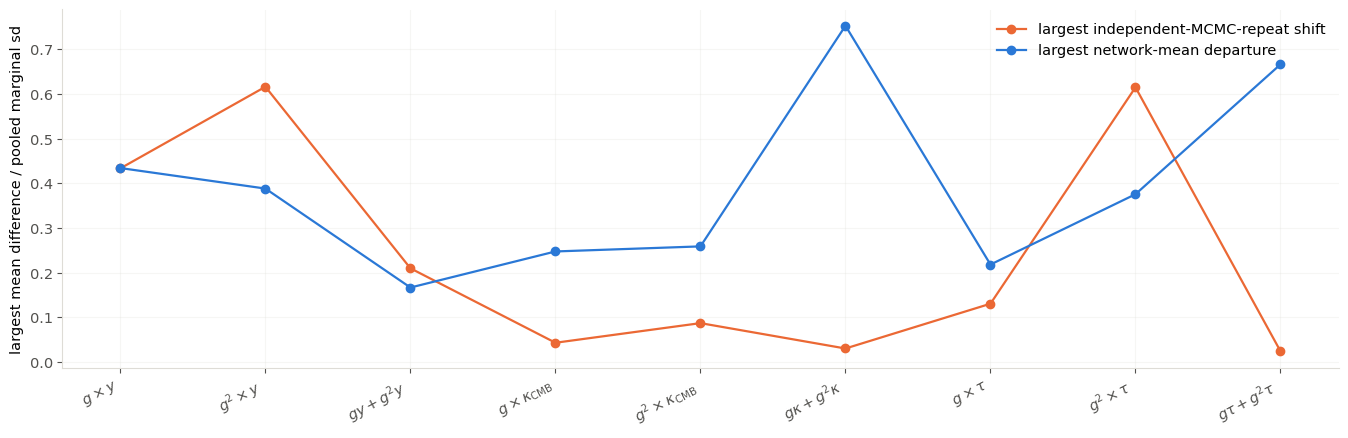

probe                   repeat   network       held-out mean logp (four networks)
gy                       0.433     0.434    -3.606    -3.787    -3.129    -3.552
g2y                      0.616     0.388    -4.011    -4.115    -4.562    -3.581
gy_g2y                   0.210     0.167    -6.147    -4.873    -6.427    -4.820
gkappa                   0.043     0.247    -1.426    -1.612    -1.631    -1.723
g2kappa                  0.087     0.259    -1.259    -1.338    -1.394    -1.362
gkappa_g2kappa           0.030     0.752    -1.426    -1.243    -1.223    -1.248
gtau                     0.131     0.218    -3.704    -3.717    -3.459    -4.971
g2tau                    0.615     0.376    -2.778    -2.890    -3.348    -3.735
gtau_g2tau               0.024     0.666    -6.780    -5.410    -7.521    -7.084


In [9]:
repeat_shift = np.array([
    all256_man[p]["max_independent_mcmc_repeat_mean_shift_sigma"]
    for p in ALL256_PROBES
])
network_shift = np.array([
    all256_man[p]["max_network_mean_departure_sigma"]
    for p in ALL256_PROBES
])
x = np.arange(len(ALL256_PROBES))
fig, ax = plt.subplots(figsize=(13.6, 4.5))
ax.plot(x, repeat_shift, "o-", color=ORANGE, lw=1.6,
        label="largest independent-MCMC-repeat shift")
ax.plot(x, network_shift, "o-", color=BLUE, lw=1.6,
        label="largest network-mean departure")
ax.set_xticks(x, [ALL256_NAMES[p] for p in ALL256_PROBES],
              rotation=28, ha="right")
ax.set_ylabel("largest mean difference / pooled marginal sd")
ax.grid(alpha=.25, color=GRID)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(ALL256_FIG_DIR / "all256_sampler_and_network_stability.png",
            dpi=180, bbox_inches="tight")
plt.show()

print(f"{'probe':20s} {'repeat':>9s} {'network':>9s} "
      f"{'held-out mean logp (four networks)':>40s}")
for probe in ALL256_PROBES:
    man = all256_man[probe]
    heldout = [record["heldout_mean_log_prob"] for record in man["per_network"]]
    print(f"{probe:20s} "
          f"{man['max_independent_mcmc_repeat_mean_shift_sigma']:9.3f} "
          f"{man['max_network_mean_departure_sigma']:9.3f} "
          + " ".join(f"{v:9.3f}" for v in heldout))


### Score-compression support

Diamonds show each noiseless observed score; violins show the corresponding 1,725
combined/native training rows. Single-statistic panels reconstruct one 5D score. Each joint
panel reconstructs the two separately normalized 5D scores and concatenates them to 10D.
An isolated diamond would indicate that the observation
is outside the simulated summary cloud even if the posterior looks smooth.


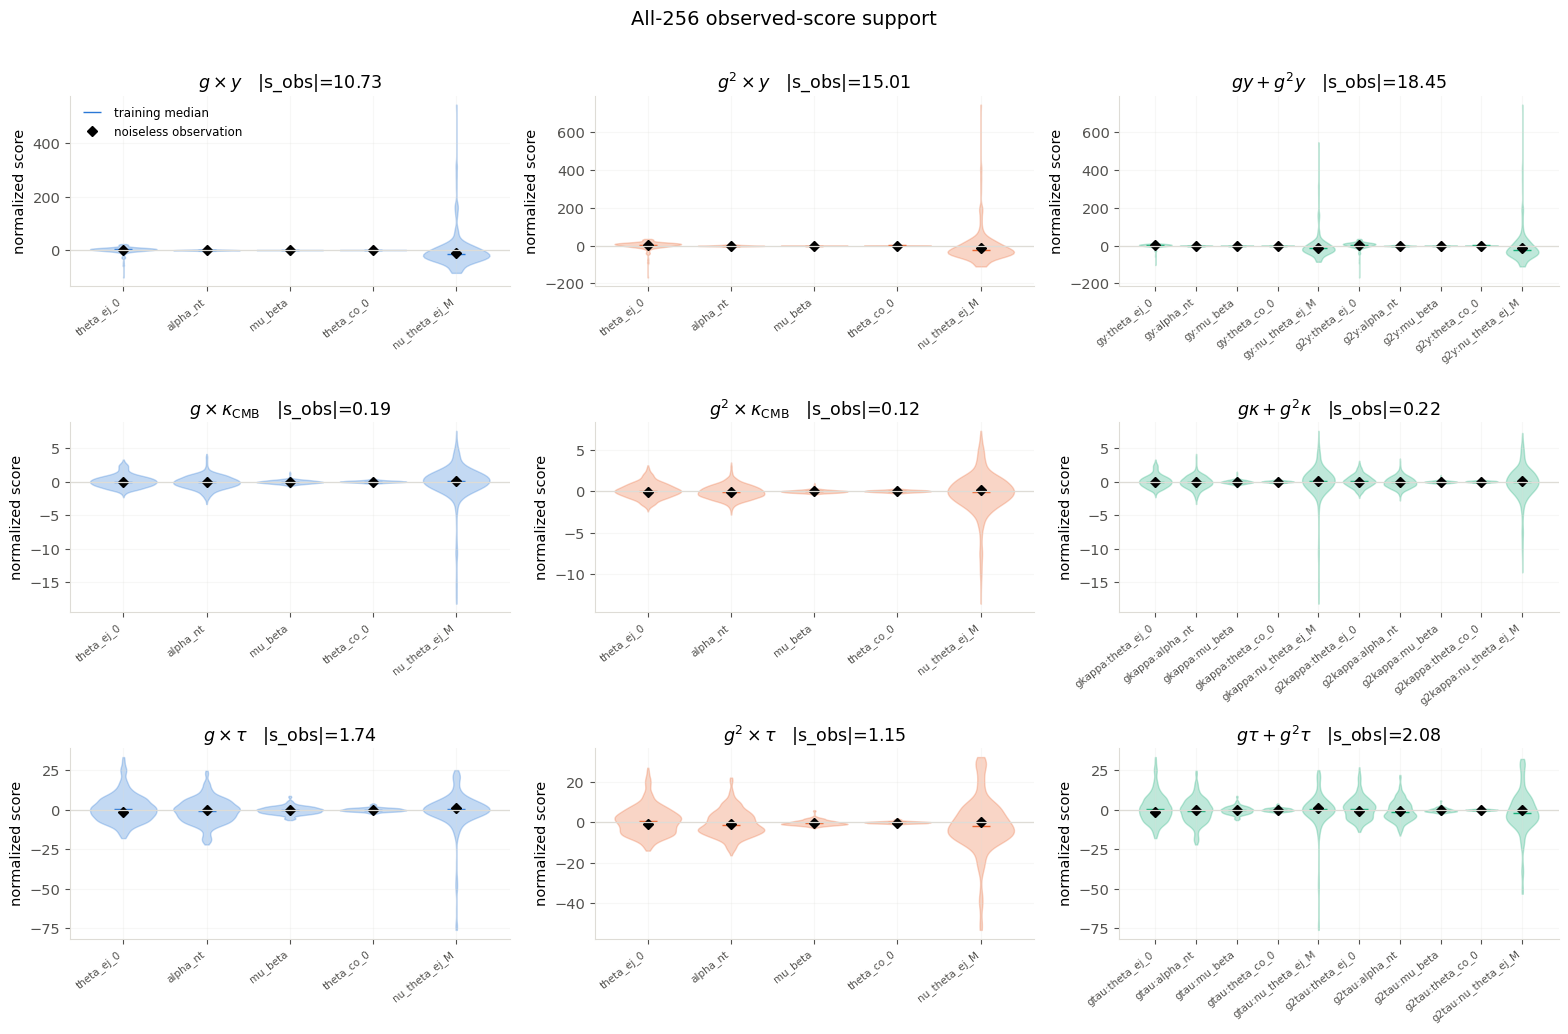

In [10]:
BLOCK = {"y": np.arange(14), "kappa": np.arange(14, 28),
         "tau": np.arange(28, 42)}
SPEC = {
    "gy": (True, False, "y"), "g2y": (False, True, "y"),
    "gy_g2y": (True, True, "y"),
    "gkappa": (True, False, "kappa"),
    "g2kappa": (False, True, "kappa"),
    "gkappa_g2kappa": (True, True, "kappa"),
    "gtau": (True, False, "tau"), "g2tau": (False, True, "tau"),
    "gtau_g2tau": (True, True, "tau"),
}
def select_stat(probe, gx, g2x):
    use_gx, use_g2x, field = SPEC[probe]
    pieces = []
    if use_gx:
        pieces.append(np.asarray(gx)[..., BLOCK[field]])
    if use_g2x:
        pieces.append(np.asarray(g2x)[..., BLOCK[field]])
    return pieces[0] if len(pieces) == 1 else np.concatenate(pieces, axis=-1)

train_rows = all256_split[all256_point_index] == 0
gx = np.asarray(all256_master["gx"], dtype=float)
g2x = np.asarray(all256_master["g2x"], dtype=float)
gx_obs = np.asarray(all256_master["gx_data_vector"], dtype=float)
g2x_obs = np.asarray(all256_master["g2x_data_vector"], dtype=float)

fig, axes = plt.subplots(3, 3, figsize=(15.8, 10.2))
for panel, (ax, probe) in enumerate(zip(axes.flat, ALL256_PROBES)):
    post, man = all256_posts[probe], all256_man[probe]
    if probe in ALL256_JOINT_PROBES:
        score_parts, observed_parts, tick_labels = [], [], []
        for component in man["component_order"]:
            rows = select_stat(component, gx, g2x)[train_rows]
            observation = select_stat(component, gx_obs, g2x_obs)
            cholesky = np.asarray(post[f"score_cholesky_{component}"], dtype=float)
            operator = np.asarray(post[f"score_operator_{component}"], dtype=float)
            reference = np.asarray(
                post[f"score_reference_prediction_{component}"], dtype=float
            )
            component_scores = (
                operator @ np.linalg.solve(cholesky, (rows-reference).T)
            ).T
            component_observed = operator @ np.linalg.solve(
                cholesky, observation-reference
            )
            np.testing.assert_allclose(
                component_observed, post[f"observed_score_{component}"],
                rtol=0, atol=1e-12,
            )
            score_parts.append(component_scores)
            observed_parts.append(component_observed)
            tick_labels.extend([f"{component}:{name}" for name in PARAMS])
        scores = np.concatenate(score_parts, axis=1)
        observed = np.concatenate(observed_parts)
    else:
        rows = select_stat(probe, gx, g2x)[train_rows]
        observation = select_stat(probe, gx_obs, g2x_obs)
        covariance = np.asarray(post["covariance"], dtype=float)
        cholesky = np.linalg.cholesky(covariance)
        operator = np.asarray(post["score_operator"], dtype=float)
        reference = np.asarray(post["score_reference_prediction"], dtype=float)
        scores = (operator @ np.linalg.solve(cholesky, (rows-reference).T)).T
        observed = operator @ np.linalg.solve(cholesky, observation-reference)
        tick_labels = list(PARAMS)
    saved_observed = np.asarray(man["observed_summary"], dtype=float)
    np.testing.assert_allclose(observed,saved_observed,rtol=0,atol=1e-12,)
    dimensions = scores.shape[1]
    _require(dimensions == man["summary_dimension"],
             f"{probe}: reconstructed summary dimension differs")
    positions = np.arange(dimensions)
    violins = ax.violinplot([scores[:, j] for j in positions],
                            positions=positions, showextrema=False, widths=.8)
    color = ALL256_COLORS[panel % 3]
    for body in violins["bodies"]:
        body.set_facecolor(color); body.set_edgecolor(color); body.set_alpha(.28)
    ax.plot(positions, np.median(scores, axis=0), "_", ms=13, color=color,
            label="training median")
    ax.plot(positions, observed, "D", ms=5.2, color="black",
            label="noiseless observation")
    ax.axhline(0, color=GRID, lw=.9)
    ax.set_title(f"{ALL256_NAMES[probe]}   |s_obs|={np.linalg.norm(observed):.2f}")
    ax.set_xticks(positions, tick_labels, rotation=38, ha="right", fontsize=7.5)
    ax.set_ylabel("normalized score")
    ax.grid(alpha=.22, color=GRID)
axes[0, 0].legend(frameon=False, fontsize=8.5)
fig.suptitle("All-256 observed-score support", y=1.01, fontsize=14)
fig.tight_layout()
fig.savefig(ALL256_FIG_DIR / "all256_score_support.png",
            dpi=180, bbox_inches="tight")
plt.show()


### Measured $gX$--$g^2X$ noise cross-correlation

Each joint result stores a diagnostic $28\times28$ covariance fitted from paired
within-point residuals. It is not used for whitening: the fitted input is the 10D
concatenation of separately normalized component scores. Pairing is retained row by row,
so SNLE can still learn dependence and the separate posterior factors must not simply be
multiplied.


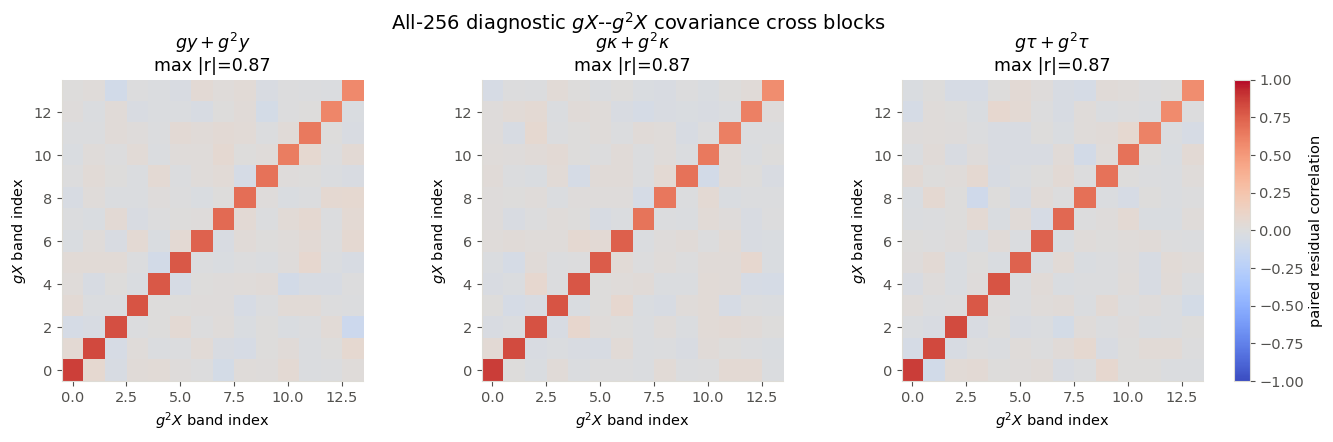

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13.8, 4.1),
                         constrained_layout=True)
for ax, (_, _, probes) in zip(axes, ALL256_FIELDS):
    joint = probes[2]
    covariance = np.asarray(
        all256_posts[joint]["raw_joint_covariance_diagnostic"], dtype=float
    )
    _require(covariance.shape == (28, 28), f"{joint}: covariance is not 28×28")
    sigma = np.sqrt(np.diag(covariance))
    cross = (covariance / np.outer(sigma, sigma))[:14, 14:]
    image = ax.imshow(cross, origin="lower", vmin=-1, vmax=1,
                      cmap="coolwarm", aspect="equal")
    ax.set_title(f"{ALL256_NAMES[joint]}\nmax |r|={np.max(np.abs(cross)):.2f}")
    ax.set_xlabel(r"$g^2X$ band index")
    ax.set_ylabel(r"$gX$ band index")
fig.colorbar(image, ax=axes, fraction=.025, pad=.025,
             label="paired residual correlation")
fig.suptitle(r"All-256 diagnostic $gX$--$g^2X$ covariance cross blocks",
             y=1.04, fontsize=14)
fig.savefig(ALL256_FIG_DIR / "all256_gx_g2x_cross_correlation.png",
            dpi=180, bbox_inches="tight")
plt.show()


### Three posterior comparisons, grouped by $X$

This cell makes exactly three figures. The $y$, $\kappa$, and $\tau$ plots each overlay
the corresponding $gX$, $g^2X$, and paired $gX+g^2X$ posterior with 68% and 95%
contours. Open circles are the 256 design points; dashed lines mark the generating point.


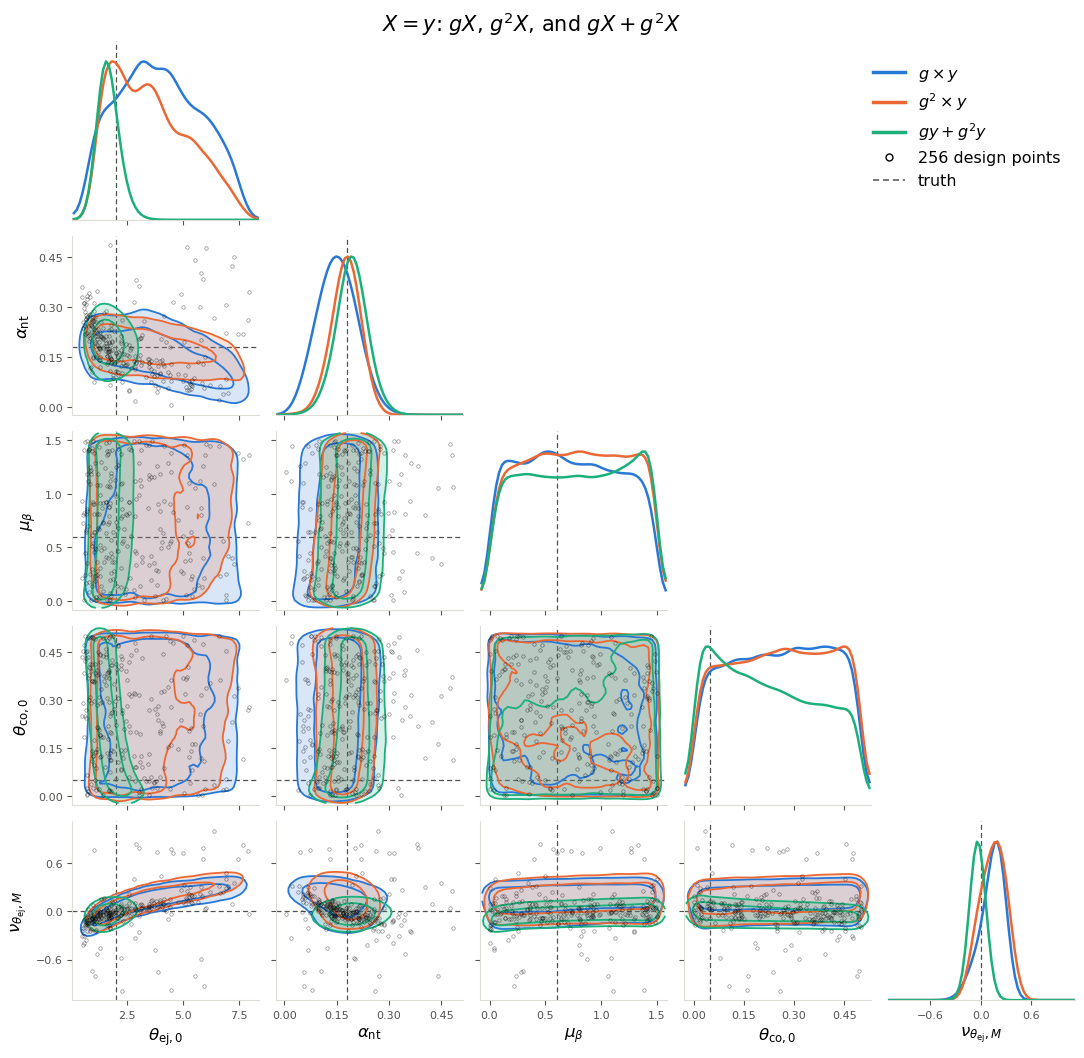

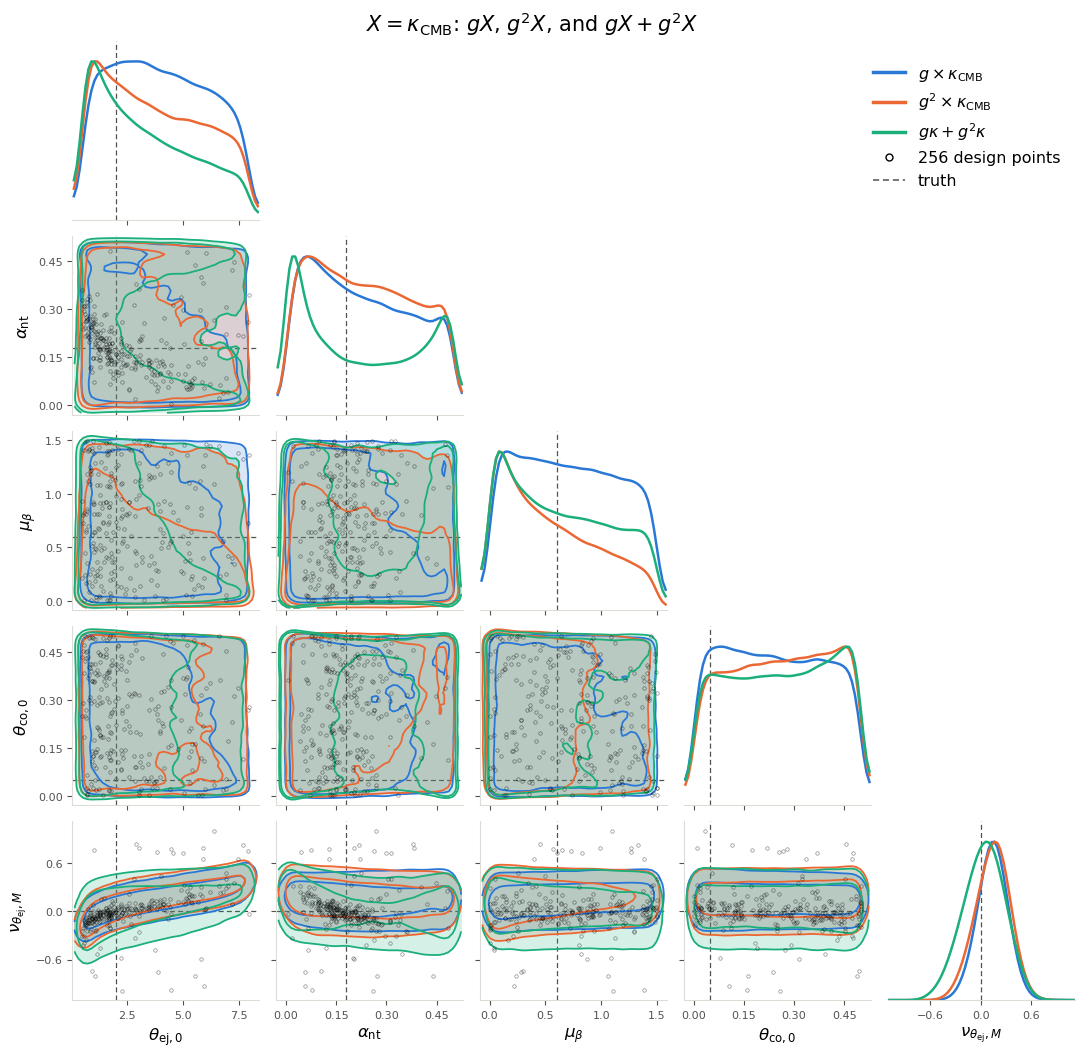

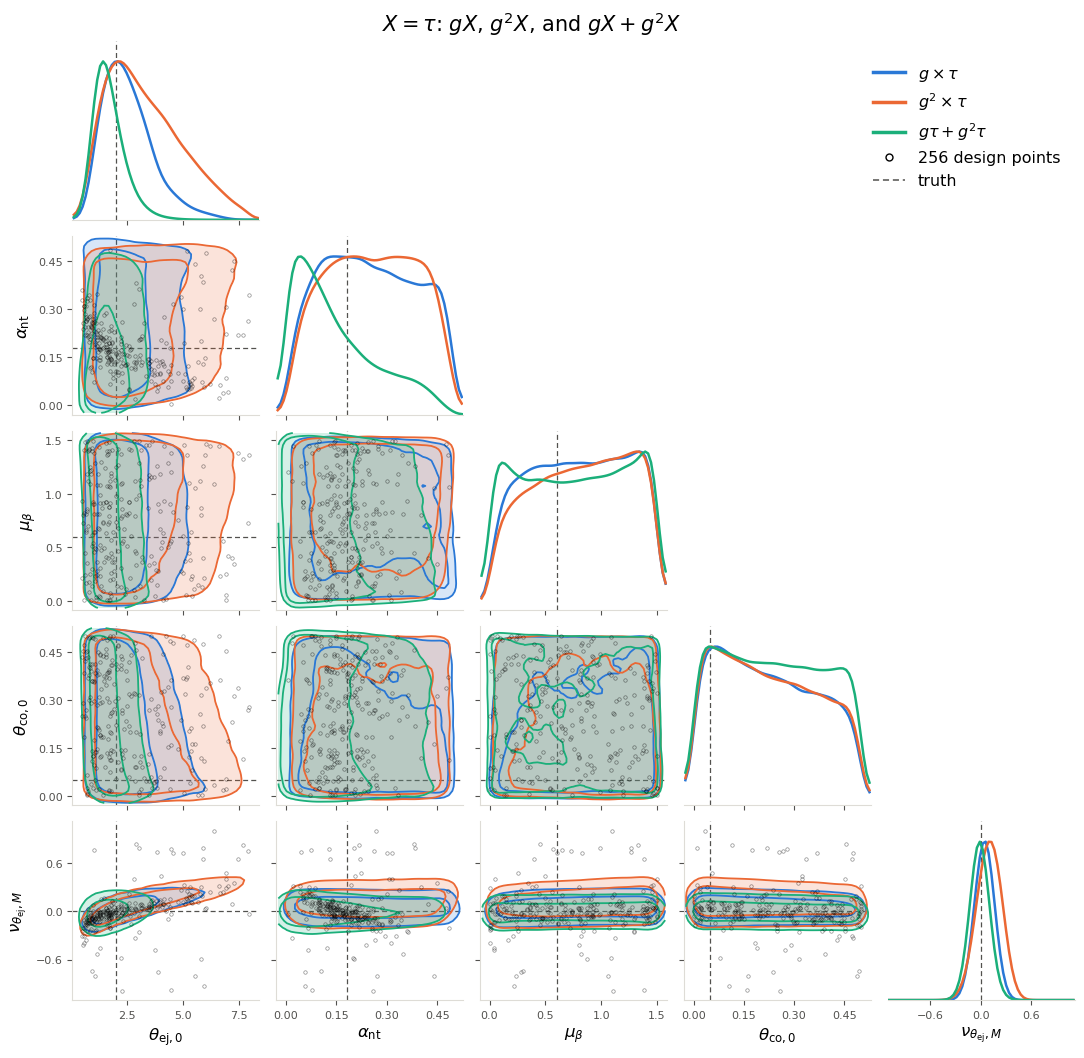

In [12]:
from scipy.ndimage import gaussian_filter
from matplotlib.lines import Line2D

def all256_triangle(chains, colors, names, points, truth):
    n, b1, s1, b2, s2 = 5, 64, 2.4, 44, 1.35
    lo, hi = np.empty(n), np.empty(n)
    for j in range(n):
        q = np.concatenate(
            [*(np.percentile(c[:, j], [0.3, 99.7]) for c in chains),
             points[:, j], [truth[j]]]
        )
        pad = .06 * max(np.ptp(q), np.finfo(float).eps)
        lo[j], hi[j] = q.min()-pad, q.max()+pad

    fig, axes = plt.subplots(n, n, figsize=(11.2, 10.6))
    for i in range(n):
        for j in range(n):
            ax = axes[i, j]
            if j > i:
                ax.axis("off")
                continue
            if i == j:
                for chain, color in zip(chains, colors):
                    h, edge = np.histogram(chain[:, j], bins=b1,
                                           range=(lo[j], hi[j]), density=True)
                    h = gaussian_filter(h, s1)
                    if h.max() > 0:
                        ax.plot(.5*(edge[:-1]+edge[1:]), h/h.max(),
                                color=color, lw=1.8)
                ax.set_ylim(0, 1.13); ax.set_yticks([])
                ax.spines["left"].set_visible(False)
            else:
                for order, (chain, color) in enumerate(zip(chains, colors)):
                    h, xe, ye = np.histogram2d(
                        chain[:, j], chain[:, i], bins=b2,
                        range=[[lo[j], hi[j]], [lo[i], hi[i]]],
                    )
                    h = gaussian_filter(h.T, s2)
                    if h.max() <= 0:
                        continue
                    ranked = np.sort(h.ravel())[::-1]
                    cumulative = np.cumsum(ranked) / ranked.sum()
                    levels = sorted({
                        float(ranked[min(int(np.searchsorted(cumulative, f)),
                                         ranked.size-1)])
                        for f in (.68, .95)
                    })
                    xc, yc = .5*(xe[:-1]+xe[1:]), .5*(ye[:-1]+ye[1:])
                    ax.contourf(xc, yc, h, levels=levels+[h.max()*1.001],
                                colors=color, alpha=.18, zorder=1+order)
                    ax.contour(xc, yc, h, levels=levels, colors=color,
                               linewidths=1.3, zorder=5+order)
                ax.plot(points[:, j], points[:, i], "o", ms=2.5,
                        mfc="none", mec="black", mew=.5, alpha=.45, zorder=20)
                ax.set_ylim(lo[i], hi[i])
            ax.axvline(truth[j], color=INK2, lw=.9,
                       ls=(0, (4, 2.5)), zorder=0)
            if i != j:
                ax.axhline(truth[i], color=INK2, lw=.9,
                           ls=(0, (4, 2.5)), zorder=0)
            ax.set_xlim(lo[j], hi[j]); ax.tick_params(labelsize=8)
            ax.xaxis.set_major_locator(plt.MaxNLocator(4, prune="both"))
            if i != j:
                ax.yaxis.set_major_locator(plt.MaxNLocator(4, prune="both"))
            if i == n-1:
                ax.set_xlabel(LABELS[j], fontsize=12)
            else:
                ax.set_xticklabels([])
            if j == 0 and i > 0:
                ax.set_ylabel(LABELS[i], fontsize=12)
            elif j != 0:
                ax.set_yticklabels([])

    handles = [Line2D([], [], color=c, lw=2.5, label=name)
               for c, name in zip(colors, names)]
    handles += [
        Line2D([], [], color="black", marker="o", ms=5, mfc="none",
               ls="none", label="256 design points"),
        Line2D([], [], color=INK2, lw=1.1, ls=(0, (4, 2.5)), label="truth"),
    ]
    fig.legend(handles=handles, loc="upper right", bbox_to_anchor=(.985, .975),
               frameon=False, fontsize=11.5)
    fig.subplots_adjust(left=.09, right=.985, top=.985, bottom=.08,
                        wspace=.09, hspace=.09)
    return fig

all256_theta = {
    p: np.asarray(all256_posts[p]["theta"], dtype=float) for p in ALL256_PROBES
}
all256_figures = {}
for field, symbol, probes in ALL256_FIELDS:
    fig = all256_triangle(
        [all256_theta[p] for p in probes], ALL256_COLORS,
        [ALL256_NAMES[p] for p in probes], all256_design_theta, all256_truth,
    )
    fig.suptitle(rf"$X={symbol.strip('$')}$: $gX$, $g^2X$, and $gX+g^2X$",
                 fontsize=15, y=1.015)
    for ext in ("png", "pdf"):
        fig.savefig(ALL256_FIG_DIR /
                    f"all256_{field}_gx_g2x_joint_triangle.{ext}",
                    dpi=180, bbox_inches="tight")
    all256_figures[field] = fig
    plt.show()


### Incremental marginal-width comparison

These heatmaps compare pooled 90% marginal widths. Values below one mean that the paired
posterior is narrower than the indicated component for this one fixed observation; they
are not a coverage or calibration claim.


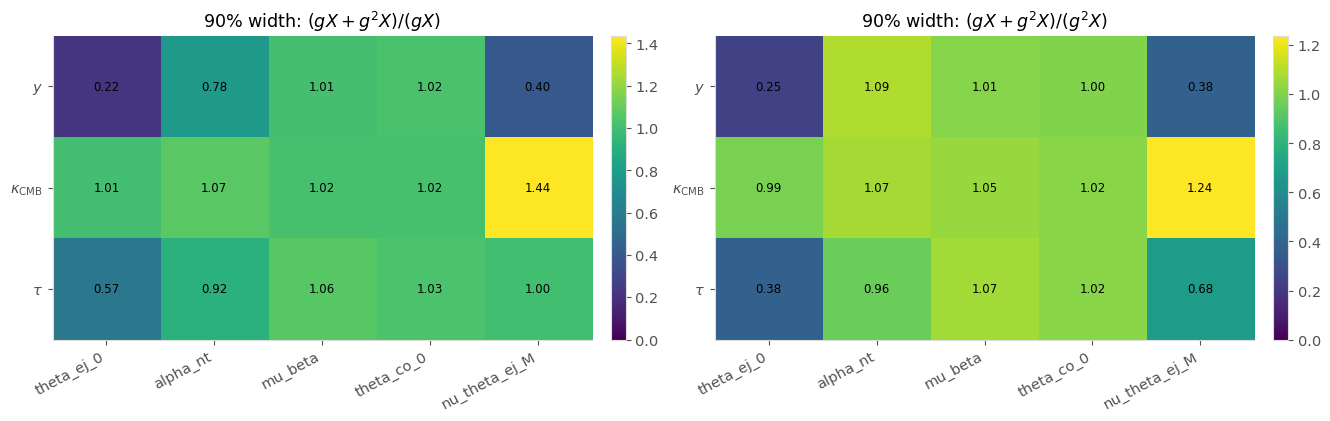

X        parameter          joint/gX   joint/g2X
y        theta_ej_0            0.223       0.245
y        alpha_nt              0.777       1.092
y        mu_beta               1.014       1.013
y        theta_co_0            1.023       1.005
y        nu_theta_ej_M         0.397       0.384
kappa    theta_ej_0            1.009       0.987
kappa    alpha_nt              1.071       1.074
kappa    mu_beta               1.018       1.049
kappa    theta_co_0            1.021       1.019
kappa    nu_theta_ej_M         1.436       1.239
tau      theta_ej_0            0.567       0.384
tau      alpha_nt              0.916       0.961
tau      mu_beta               1.064       1.067
tau      theta_co_0            1.029       1.019
tau      nu_theta_ej_M         0.999       0.683


In [13]:
def width90(samples):
    return np.percentile(samples, 95, axis=0) - np.percentile(samples, 5, axis=0)

joint_over_gx = np.empty((3, 5))
joint_over_g2x = np.empty((3, 5))
for row, (_, _, probes) in enumerate(ALL256_FIELDS):
    gx_probe, g2x_probe, joint = probes
    joint_over_gx[row] = width90(all256_theta[joint]) / width90(all256_theta[gx_probe])
    joint_over_g2x[row] = width90(all256_theta[joint]) / width90(all256_theta[g2x_probe])

fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.1), constrained_layout=True)
panels = [
    (joint_over_gx, r"90% width: $(gX+g^2X)/(gX)$"),
    (joint_over_g2x, r"90% width: $(gX+g^2X)/(g^2X)$"),
]
rows = [r"$y$", r"$\kappa_{\rm CMB}$", r"$\tau$"]
for ax, (values, title) in zip(axes, panels):
    image = ax.imshow(values, cmap="viridis", aspect="auto", vmin=0)
    ax.set_title(title)
    ax.set_xticks(range(5), PARAMS, rotation=28, ha="right")
    ax.set_yticks(range(3), rows)
    for i in range(3):
        for j in range(5):
            ax.text(j, i, f"{values[i, j]:.2f}",
                    ha="center", va="center", fontsize=8.5)
    fig.colorbar(image, ax=ax, fraction=.045, pad=.035)
fig.savefig(ALL256_FIG_DIR / "all256_joint_marginal_width_ratios.png",
            dpi=180, bbox_inches="tight")
plt.show()

print(f"{'X':8s} {'parameter':16s} {'joint/gX':>10s} {'joint/g2X':>11s}")
for row, (field, _, _) in enumerate(ALL256_FIELDS):
    for j, parameter in enumerate(PARAMS):
        print(f"{field:8s} {parameter:16s} "
              f"{joint_over_gx[row, j]:10.3f} {joint_over_g2x[row, j]:11.3f}")


**Interpretation boundary.** Early stopping and smooth contours do not by themselves show
convergence. Inspect independent-MCMC-repeat stability, between-network stability,
held-out likelihoods, and observed-score support for every probe. The point-level holdout
prevents direct point leakage, but calibrated coverage still requires a repeated-observation
study. The combined product also retains the warning that the repaired old and new cohorts
come from different scientific source snapshots.


gkappa   covariance             max |difference| = 0.000e+00
gkappa   score operator         max |difference| = 0.000e+00
gkappa   reference prediction   max |difference| = 0.000e+00
gkappa   observed score         max |difference| = 0.000e+00
g2kappa  covariance             max |difference| = 0.000e+00
g2kappa  score operator         max |difference| = 0.000e+00
g2kappa  reference prediction   max |difference| = 0.000e+00
g2kappa  observed score         max |difference| = 0.000e+00
PASS: the joint run uses the same component normalizations and observations as the individual runs


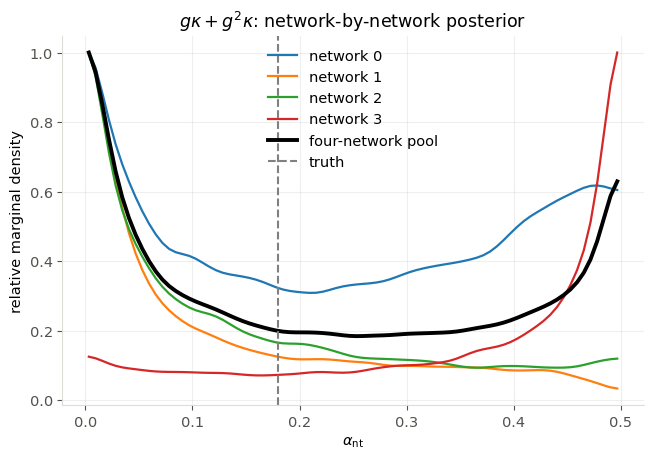

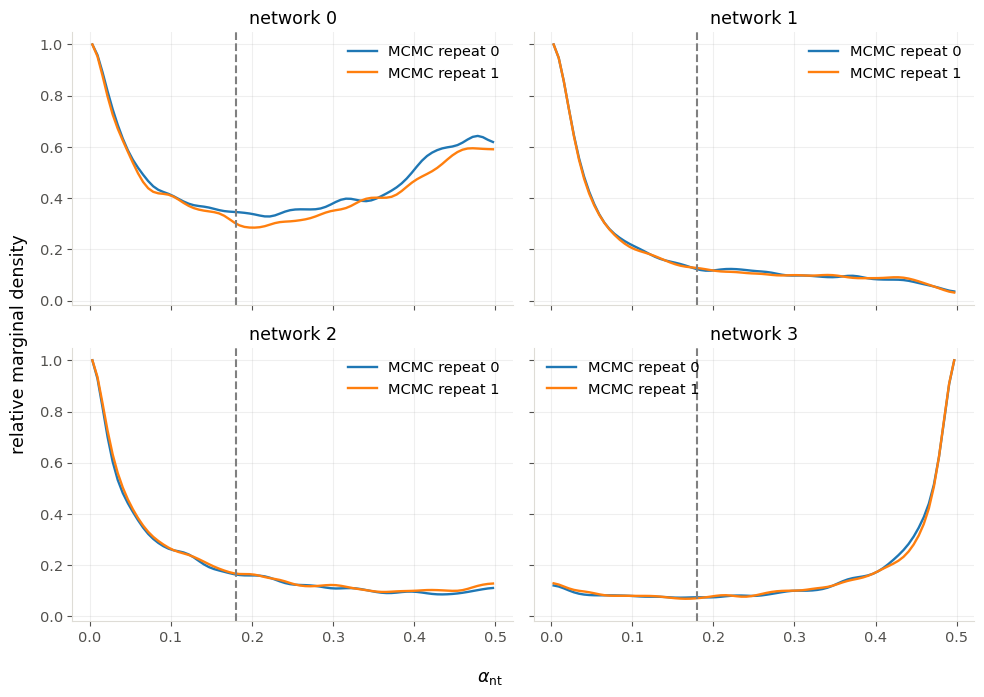

In [14]:
from scipy.ndimage import gaussian_filter1d

probe = "gkappa_g2kappa"
components = ("gkappa", "g2kappa")
joint_post = all256_posts[probe]
joint_man = all256_man[probe]

# Confirm that the two joint components use exactly the same score contracts
# and observed scores as their respective individual analyses.
_require(
    tuple(joint_man["component_order"]) == components,
    f"unexpected component order: {joint_man['component_order']}",
)

for component in components:
    single_post = all256_posts[component]

    comparisons = {
        "covariance": (
            np.asarray(joint_post[f"covariance_{component}"], dtype=float),
            np.asarray(single_post["covariance"], dtype=float),
        ),
        "score operator": (
            np.asarray(joint_post[f"score_operator_{component}"], dtype=float),
            np.asarray(single_post["score_operator"], dtype=float),
        ),
        "reference prediction": (
            np.asarray(
                joint_post[f"score_reference_prediction_{component}"],
                dtype=float,
            ),
            np.asarray(
                single_post["score_reference_prediction"],
                dtype=float,
            ),
        ),
        "observed score": (
            np.asarray(
                joint_post[f"observed_score_{component}"],
                dtype=float,
            ),
            np.asarray(
                all256_man[component]["observed_summary"],
                dtype=float,
            ),
        ),
    }

    for name, (joint_value, single_value) in comparisons.items():
        _require(
            joint_value.shape == single_value.shape,
            (
                f"{component}: joint/individual {name} shapes differ: "
                f"{joint_value.shape} versus {single_value.shape}"
            ),
        )

        difference = np.max(np.abs(joint_value - single_value))
        print(f"{component:8s} {name:22s} max |difference| = {difference:.3e}")

        np.testing.assert_allclose(
            joint_value,
            single_value,
            rtol=1e-10,
            atol=1e-12,
            err_msg=f"{component}: joint and individual {name} differ",
        )

print("PASS: the joint run uses the same component normalizations "
    "and observations as the individual runs")


alpha_index = PARAMS.index("alpha_nt")
edges = np.linspace(0.0, 0.5, 81)
centres = 0.5 * (edges[:-1] + edges[1:])

def marginal_curve(values):
    density, _ = np.histogram(values, bins=edges, density=True)
    density = gaussian_filter1d(density.astype(float), 2.0)
    return density / density.max()


# Compare the four independently trained neural likelihoods.
fig, ax = plt.subplots(figsize=(7.5, 4.8))

for seed in range(joint_man["network_seeds"]):
    values = np.asarray(
        joint_post[f"theta_seed_{seed}"], dtype=float
    )[:, alpha_index]

    ax.plot(
        centres,
        marginal_curve(values),
        lw=1.6,
        label=f"network {seed}",
    )

pooled = np.asarray(joint_post["theta"], dtype=float)[:, alpha_index]
ax.plot(
    centres,
    marginal_curve(pooled),
    color="black",
    lw=2.8,
    label="four-network pool",
)

ax.axvline(all256_truth[alpha_index], color="grey", ls="--", label="truth")
ax.set_xlabel(r"$\alpha_{\rm nt}$")
ax.set_ylabel("relative marginal density")
ax.set_title(r"$g\kappa+g^2\kappa$: network-by-network posterior")
ax.legend(frameon=False)
ax.grid(alpha=0.2)
plt.show()


# Compare the two independent MCMC repeats within each network.
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True, sharey=True)

for seed, ax in enumerate(axes.flat):
    values = np.asarray(
        joint_post[f"theta_seed_{seed}"], dtype=float
    )[:, alpha_index]

    half = values.size // 2
    repeats = (values[:half], values[half:])

    for repeat, sample in enumerate(repeats):
        ax.plot(
            centres,
            marginal_curve(sample),
            lw=1.7,
            label=f"MCMC repeat {repeat}",
        )

    ax.axvline(all256_truth[alpha_index], color="grey", ls="--")
    ax.set_title(f"network {seed}")
    ax.grid(alpha=0.2)
    ax.legend(frameon=False)

fig.supxlabel(r"$\alpha_{\rm nt}$")
fig.supylabel("relative marginal density")
fig.tight_layout()
plt.show()

In [15]:
# Load and validate the two new 15D cross-field joint posteriors.

ALLFIELD_COMPONENTS = {
    "gy_gkappa_gtau": ("gy", "gkappa", "gtau"),
    "g2y_g2kappa_g2tau": ("g2y", "g2kappa", "g2tau"),
}

ALLFIELD_POST_FILES = {
    probe: (
        ALL256_DIR
        / f"mock_snle_all256_{ALL256_RUN_LABEL}_sepscore15_{probe}_posterior.npz"
    )
    for probe in ALLFIELD_COMPONENTS
}

required = []
for path in ALLFIELD_POST_FILES.values():
    required.extend([path, path.with_suffix(".json")])

missing = [path for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError(
        "Missing cross-field all-256 results:\n  "
        + "\n  ".join(map(str, missing))
    )

allfield_posts = {
    probe: np.load(path, allow_pickle=False)
    for probe, path in ALLFIELD_POST_FILES.items()
}
allfield_man = {
    probe: _manifest(post)
    for probe, post in allfield_posts.items()
}

for probe, components in ALLFIELD_COMPONENTS.items():
    path = ALLFIELD_POST_FILES[probe]
    post = allfield_posts[probe]
    man = allfield_man[probe]

    _require(
        json.loads(path.with_suffix(".json").read_text()) == man,
        f"{probe}: NPZ manifest and JSON sidecar differ",
    )
    _require(
        man["schema_version"]
        == "godmax.mock_sbi.all256_native_snle_separate_score_concat15.v1",
        f"{probe}: unexpected schema {man['schema_version']!r}",
    )
    _require(
        man["analysis_status"]
        == "exploratory_two_snapshot_all256_separate_score_concat15",
        f"{probe}: unexpected analysis status",
    )
    _require(man["probe"] == probe, f"{probe}: probe label mismatch")
    _require(
        tuple(man["component_order"]) == components,
        f"{probe}: component order differs",
    )
    _require(
        man["summary_dimension"] == 15,
        f"{probe}: expected a 15D summary",
    )
    _require(
        man["score_contract"]["component_summary_dimensions"] == [5, 5, 5],
        f"{probe}: component summaries are not 5+5+5",
    )
    _require(
        man["score_contract"]["literal_component_addition"] is False,
        f"{probe}: components were added",
    )
    _require(
        man["score_contract"]["raw_joint_covariance_used_for_whitening"] is False,
        f"{probe}: components were jointly whitened",
    )
    _require(
        (
            man["cohort"],
            man["training_replica_policy"],
            man["contract_replica_policy"],
        )
        == ("combined", "native", "native"),
        f"{probe}: unexpected cohort or replica policy",
    )
    _require(
        tuple(man["parameter_names"]) == tuple(PARAMS),
        f"{probe}: parameter order differs",
    )
    _require(
        man["point_split_sha256"] == split_info["sha256"],
        f"{probe}: point-split hash differs",
    )
    _require(
        np.array_equal(np.asarray(post["point_split"]), all256_split),
        f"{probe}: point-split array differs",
    )

    theta = np.asarray(post["theta"], dtype=float)
    u = np.asarray(post["u"], dtype=float)

    _require(
        theta.ndim == 2 and theta.shape[1] == 5,
        f"{probe}: invalid theta shape {theta.shape}",
    )
    _require(
        u.shape == theta.shape,
        f"{probe}: u shape {u.shape} differs from theta {theta.shape}",
    )
    _require(
        theta.shape[0] == man["pooled_samples"],
        f"{probe}: pooled sample count differs",
    )
    _require(
        man["posterior_samples_per_network"] * man["network_seeds"]
        == man["pooled_samples"],
        f"{probe}: inconsistent network/sample counts",
    )
    _require(
        np.asarray(post["observed_summary"]).shape == (15,),
        f"{probe}: observed summary is not 15D",
    )
    _require(
        np.asarray(post["raw_joint_covariance_diagnostic"]).shape == (42, 42),
        f"{probe}: raw diagnostic covariance is not 42x42",
    )

    np.testing.assert_allclose(
        post["theta_reference"],
        all256_truth,
        rtol=0,
        atol=0,
    )

    for component in components:
        for key in (
            f"covariance_{component}",
            f"score_cholesky_{component}",
            f"score_operator_{component}",
            f"score_reference_prediction_{component}",
            f"observed_score_{component}",
        ):
            _require(key in post.files, f"{probe}: missing {key}")

    print(
        f"{probe}: {theta.shape[0]:,} samples; "
        f"repeat shift="
        f"{man['max_independent_mcmc_repeat_mean_shift_sigma']:.3f}; "
        f"network departure="
        f"{man['max_network_mean_departure_sigma']:.3f}"
    )

# Extend only the posterior dictionaries. Do not append these probes to
# ALL256_PROBES, because the earlier 3x3 score-support figure assumes nine arms.
all256_posts.update(allfield_posts)
all256_man.update(allfield_man)
all256_theta.update({
    probe: np.asarray(post["theta"], dtype=float)
    for probe, post in allfield_posts.items()
})

gy_gkappa_gtau: 80,000 samples; repeat shift=0.079; network departure=0.371
g2y_g2kappa_g2tau: 80,000 samples; repeat shift=0.075; network departure=0.421


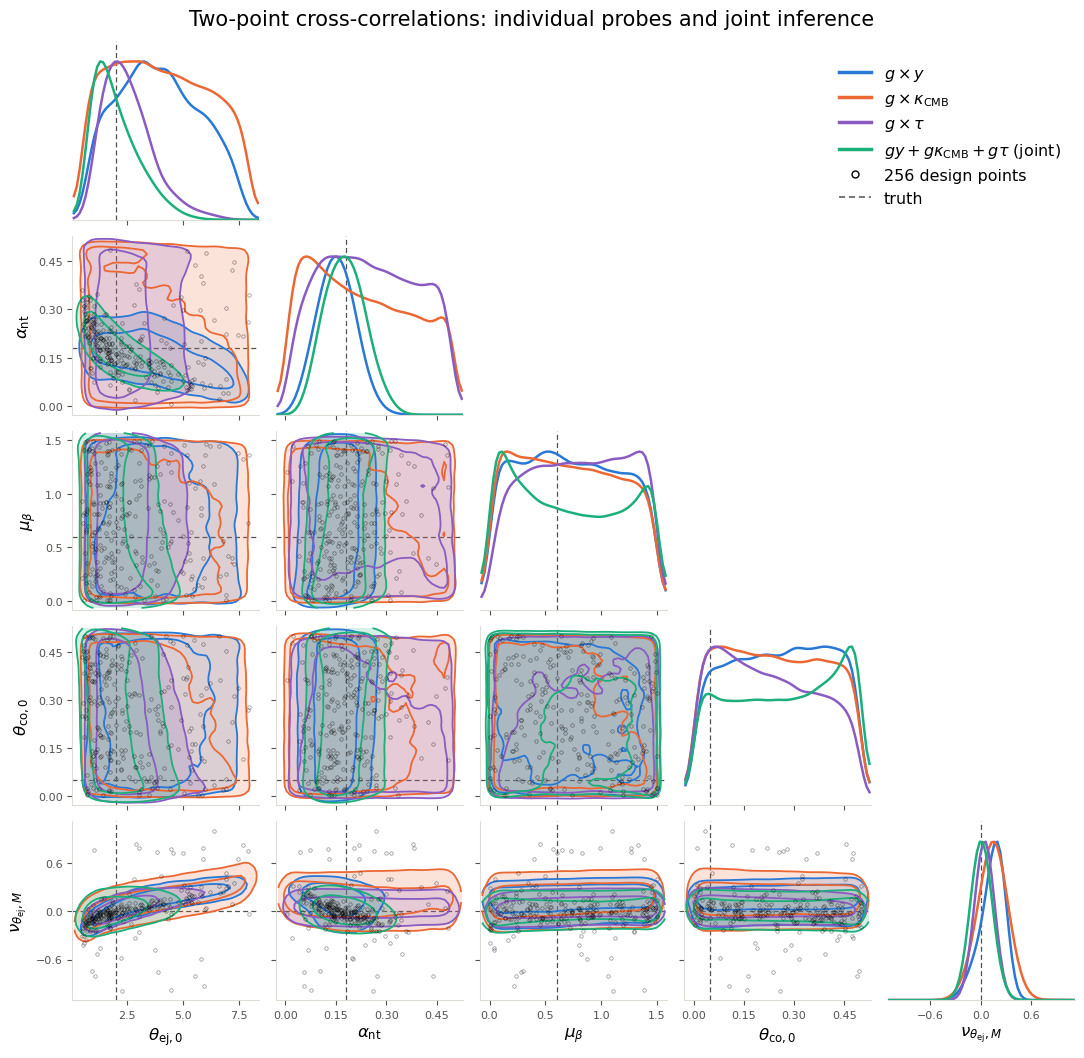

In [16]:
# Figure 1: the three individual two-point probes and their joint posterior.

TWO_POINT_PROBES = (
    "gy",
    "gkappa",
    "gtau",
    "gy_gkappa_gtau",
)

TWO_POINT_NAMES = (
    r"$g\times y$",
    r"$g\times\kappa_{\rm CMB}$",
    r"$g\times\tau$",
    r"$gy+g\kappa_{\rm CMB}+g\tau$ (joint)",
)

FOUR_CONTOUR_COLORS = (
    BLUE,
    ORANGE,
    "#8a5cc2",
    GREEN,
)

fig = all256_triangle(
    [all256_theta[probe] for probe in TWO_POINT_PROBES],
    FOUR_CONTOUR_COLORS,
    TWO_POINT_NAMES,
    all256_design_theta,
    all256_truth,
)

fig.suptitle(
    r"Two-point cross-correlations: individual probes and joint inference",
    fontsize=15,
    y=1.015,
)

for extension in ("png", "pdf"):
    fig.savefig(
        ALL256_FIG_DIR
        / f"all256_gx_threefield_joint_triangle.{extension}",
        dpi=180,
        bbox_inches="tight",
    )

plt.show()

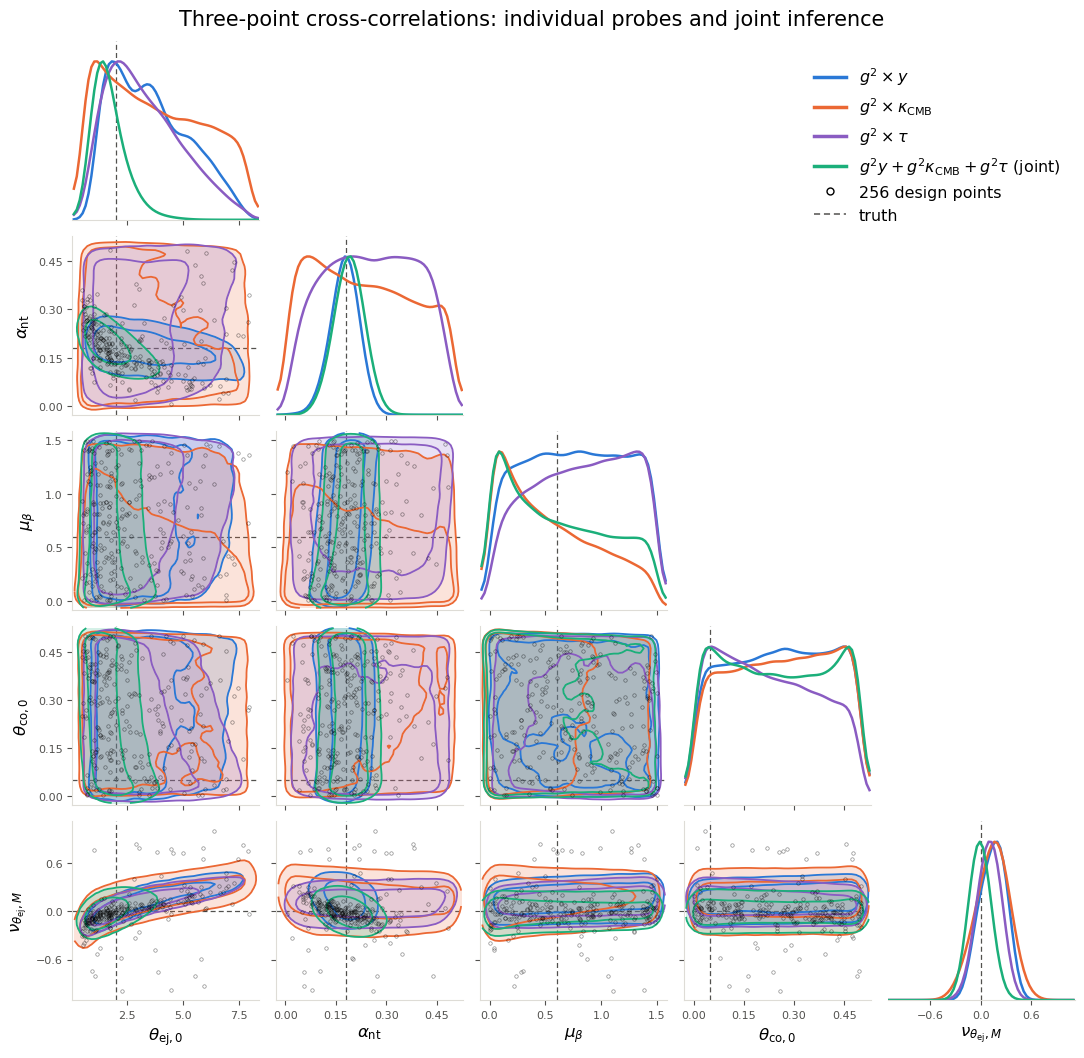

In [17]:
# Figure 2: the three individual three-point probes and their joint posterior.

THREE_POINT_PROBES = (
    "g2y",
    "g2kappa",
    "g2tau",
    "g2y_g2kappa_g2tau",
)

THREE_POINT_NAMES = (
    r"$g^2\times y$",
    r"$g^2\times\kappa_{\rm CMB}$",
    r"$g^2\times\tau$",
    r"$g^2y+g^2\kappa_{\rm CMB}+g^2\tau$ (joint)",
)

fig = all256_triangle(
    [all256_theta[probe] for probe in THREE_POINT_PROBES],
    FOUR_CONTOUR_COLORS,
    THREE_POINT_NAMES,
    all256_design_theta,
    all256_truth,
)

fig.suptitle(
    r"Three-point cross-correlations: individual probes and joint inference",
    fontsize=15,
    y=1.015,
)

for extension in ("png", "pdf"):
    fig.savefig(
        ALL256_FIG_DIR
        / f"all256_g2x_threefield_joint_triangle.{extension}",
        dpi=180,
        bbox_inches="tight",
    )

plt.show()